# Gold Rate Prediction using Machine Learning

This project uses Machine Learning to predict gold rates based on different financial and economic factors.

The dataset contains information such as USD-INR exchange rate, crude oil price, inflation, interest rate, silver rate, Sensex, and gold demand.

Linear Regression is used to build the prediction model.

## 1. Import Required Libraries

We first import the Python libraries required for data handling and machine learning.

- Pandas is used to work with the dataset.
- NumPy is used for numerical operations.
- Matplotlib is used for visualization.
- Scikit-learn is used for machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load the Dataset

The gold price dataset is loaded into a Pandas DataFrame.

The dataset contains 100 observations covering the period from 2018 to 2026.

In [3]:
data = pd.read_csv("/content/gold_price_dataset.csv")

data.head()

,Date,USD_INR,Crude_Oil,Inflation,Interest_Rate,Silver_Rate,Sensex,Gold_Demand,Gold_Rate
0,2018-01-01,63.30,59.34,5.68,5.96,33217,35389,730.3,27221
1,2018-02-01,63.15,64.53,5.87,5.97,36778,37369,678.2,29606
2,2018-03-01,63.85,66.04,6.22,6.04,39167,32912,764.9,28106
3,2018-04-01,64.61,65.39,6.30,6.03,39868,36360,799.0,27843
4,2018-05-01,63.79,69.12,5.17,6.00,38953,35044,775.5,27961


In [4]:
print("Shape:", data.shape)

print("\nColumns:")
print(data.columns)

print("\nData Types:")
print(data.dtypes)

Shape: (100, 9)

Columns:
Index(['Date', 'USD_INR', 'Crude_Oil', 'Inflation', 'Interest_Rate',
       'Silver_Rate', 'Sensex', 'Gold_Demand', 'Gold_Rate'],
      dtype='object')

Data Types:
Date              object
USD_INR          float64
Crude_Oil        float64
Inflation        float64
Interest_Rate    float64
Silver_Rate        int64
Sensex             int64
Gold_Demand      float64
Gold_Rate          int64
dtype: object


In [5]:
data.isnull().sum()

,0
Date,0
USD_INR,0
Crude_Oil,0
Inflation,0
Interest_Rate,0
Silver_Rate,0
Sensex,0
Gold_Demand,0
Gold_Rate,0


##  Basic Statistical Analysis

The describe() function gives basic statistical information such as mean, minimum, maximum, and standard deviation.

In [6]:
data.describe()

,USD_INR,Crude_Oil,Inflation,Interest_Rate,Silver_Rate,Sensex,Gold_Demand,Gold_Rate
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000
mean,74.437900,66.388500,5.537500,5.304900,66332.020000,58467.010000,727.843000,53496.34000
std,6.785782,11.469968,1.232838,0.914747,16912.079982,15270.458788,112.582283,15153.57622
min,63.150000,43.730000,3.010000,3.930000,33217.000000,32912.000000,442.500000,27221.00000
25%,68.485000,55.380000,4.392500,4.020000,53291.000000,44546.750000,645.550000,40733.00000
50%,74.585000,67.375000,5.645000,5.965000,65751.500000,59090.500000,746.000000,52385.00000
75%,80.492500,75.767500,6.590000,6.020000,80768.750000,71475.250000,816.100000,66351.25000
max,85.860000,87.870000,8.000000,6.110000,96691.000000,84566.000000,946.000000,79225.00000


##  Selecting Features and Target

For this project, Gold_Rate is the target variable that we want to predict.

The other financial and economic columns are used as features.

Date is not directly used as a feature in the first model.

In [7]:
features = [
    "USD_INR",
    "Crude_Oil",
    "Inflation",
    "Interest_Rate",
    "Silver_Rate",
    "Sensex",
    "Gold_Demand"
]

X = data[features]
y = data["Gold_Rate"]

##  Splitting the Dataset

The dataset is divided into training and testing data.

The training data is used to teach the model, while the testing data is used to evaluate how well the model predicts unseen data.

We use 80% of the data for training and 20% for testing.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80, 7)
Testing data: (20, 7)


## Linear Regression Model

Linear Regression is used to find the relationship between the input features and the gold rate.

The model learns patterns from the training data and uses them to predict the Gold_Rate for new data.

In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

## Training the model and Making prediction

In [10]:
model.fit(X_train,y_train)

LinearRegression()

In [11]:
y_pred=model.predict(X_test)

## Actual vs Predicted comparison

In [12]:
result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

result.head(10)

,Actual,Predicted
0,71400,71361.274278
1,56668,56282.859475
2,64963,64987.213816
3,50297,50566.210362
4,51187,47987.100295
5,49431,48310.745748
6,37791,39653.140877
7,69403,69434.789968
8,33330,33785.428710
9,27221,28435.964838


## Evaluating the Model

MAE
MSE
R2 score

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R² Score:", r2)

MAE: 933.4156419210718
MSE: 1434396.738875636
R² Score: 0.993735026956842


## Actual vs Predicted Visualization

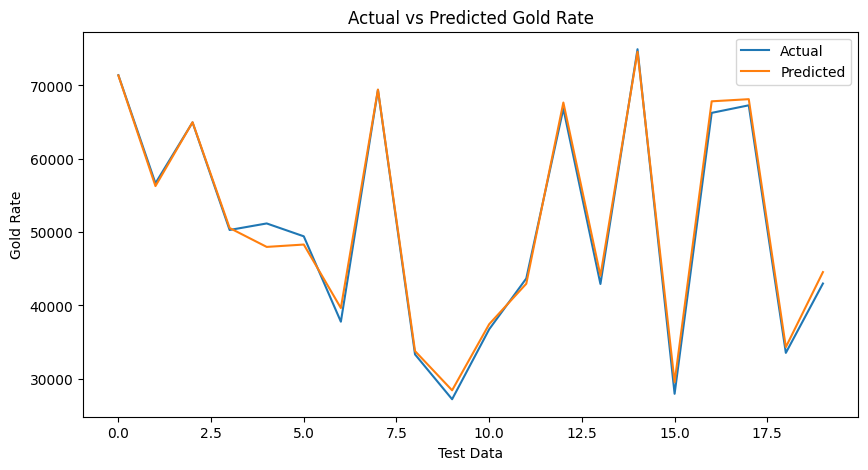

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(y_test.values, label="Actual")
plt.plot(y_pred, label="Predicted")

plt.title("Actual vs Predicted Gold Rate")
plt.xlabel("Test Data")
plt.ylabel("Gold Rate")
plt.legend()

plt.show()

## Understanding Feature Coefficients

In [17]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,USD_INR,1382.388878
1,Crude_Oil,-14.729994
2,Inflation,262.660355
3,Interest_Rate,85.554283
4,Silver_Rate,0.123422
5,Sensex,0.253412
6,Gold_Demand,1.713820


## Testing the Model with New Data

In [23]:
new_data = pd.DataFrame({
    "USD_INR": [102.4],
    "Crude_Oil": [42],
    "Inflation": [12.3],
    "Interest_Rate": [8.5],
    "Silver_Rate": [23],
    "Sensex": [8000],
    "Gold_Demand": [1000]
})

predicted_gold_rate = model.predict(new_data)

print("Predicted Gold Rate:", predicted_gold_rate[0])

Predicted Gold Rate: 74123.55436618661


## Conclusion

In this project, a Linear Regression model was used to predict Gold_Rate based on financial and economic factors.

The dataset was divided into training and testing data. The model was trained using features such as USD-INR, Crude Oil, Inflation, Interest Rate, Silver Rate, Sensex, and Gold Demand.

The model achieved an R² score of 0.9937 on the test data, showing a strong fit on this dataset. The MAE was around 933.42.

The model was also tested with new input values to generate a predicted Gold_Rate.

This project helped in understanding the basic machine learning workflow, including data preparation, train-test splitting, model training, prediction, and model evaluation.

The prediction is based on the patterns present in this dataset and should not be treated as an actual future gold-price forecast.